In [1]:
# Set up google colab
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [2]:
# Setup cell
import torch
import torch.nn as nn
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import mean_absolute_error, mean_squared_error

%matplotlib inline
plt.rcParams["figure.figsize"] = (10.0, 8.0) # Set default size of plots
plt.rcParams["image.interpolation"] = "nearest"
plt.rcParams["image.cmap"] = "gray"

In [ ]:
# Load results
sarima = pd.read_csv("/content/drive/MyDrive/sarima_results.csv",
                     index_col=0, parse_dates=True)
lstm   = pd.read_csv("/content/drive/MyDrive/lstm_results.csv",
                     index_col=0, parse_dates=True)
sarima_long = pd.read_csv("/content/drive/MyDrive/sarima_long_results.csv",
                           index_col=0, parse_dates=True)
lstm_long   = pd.read_csv("/content/drive/MyDrive/lstm_long_results.csv",
                           index_col=0, parse_dates=True)

# Shrot-term Forecasting

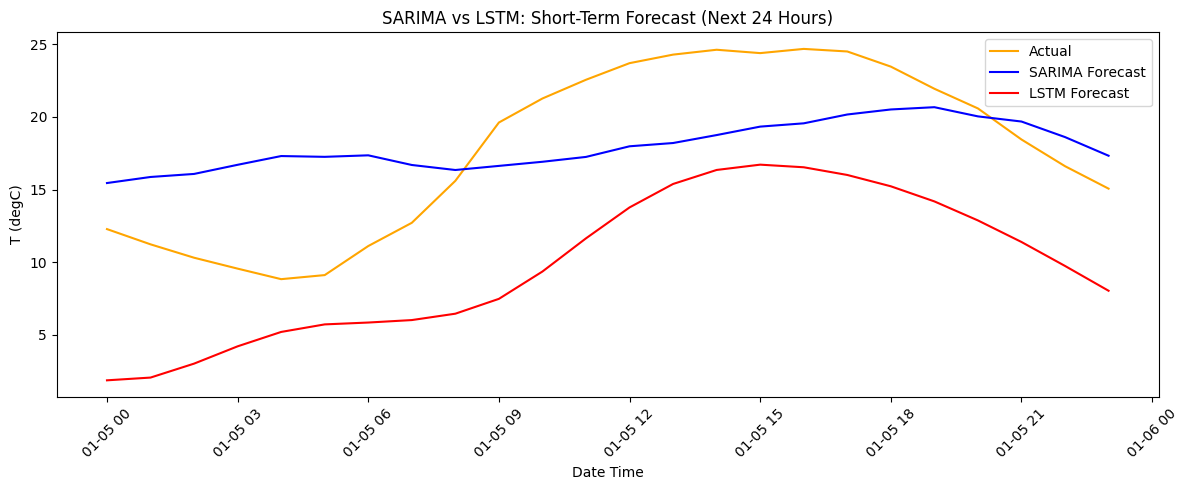

In [ ]:
# Forecast plot
plt.figure(figsize=(12, 5))
plt.plot(sarima.index, sarima["actual"],   label="Actual",         color="orange")
plt.plot(sarima.index, sarima["forecast"], label="SARIMA Forecast", color="blue")
plt.plot(lstm.index,   lstm["forecast"],   label="LSTM Forecast",   color="red")
plt.title("SARIMA vs LSTM: Short-Term Forecast")
plt.xlabel("Date Time")
plt.ylabel("T (degC)")
plt.xticks(rotation=45)
plt.legend()
plt.tight_layout()
plt.show()

In [7]:
# Metrics comparison
def evaluate(name, actual, forecast):
    rmse = np.sqrt(mean_squared_error(actual, forecast))
    print(f"{name:<10} | RMSE: {rmse:.3f}")

print("-" * 40)
evaluate("SARIMA", sarima["actual"], sarima["forecast"])
evaluate("LSTM",   lstm["actual"],   lstm["forecast"])
print("-" * 40)

----------------------------------------
SARIMA     | RMSE: 4.841
LSTM       | RMSE: 8.275
----------------------------------------
